<a href="https://colab.research.google.com/github/linda-r-wu/Problem-Set-2-Econ_5200_PS2/blob/main/ps2_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [34]:
# settings for simulation
n_experiments = 200
zero_share = 0.80
low_effect = 500
high_effect = 1500
n_min = 50
n_max = 5000
outcome_sd = 15000

# most experiments have no effect some have positive effect
with_effect = rng.random(n_experiments) >= zero_share

true_effect = np.zeros(n_experiments)
true_effect[with_effect] = rng.uniform(
    low_effect, high_effect, with_effect.sum()
)

# record the truth before adding estimation noise
truth = true_effect.copy()

# each experiment has different number of users per group
sample_size = rng.integers(n_min, n_max + 1, n_experiments)

# more users means smaller standard error
standard_error = outcome_sd * np.sqrt(2 / sample_size)

# observed estimates include random noise
estimated_effect = true_effect + rng.normal(0, standard_error)

# store all experiments
log = pd.DataFrame({
    "experiment": np.arange(1, n_experiments + 1),
    "true_effect": truth,
    "n_per_group": sample_size,
    "standard_error": standard_error,
    "estimated_effect": estimated_effect
})

print("Number of experiments:", len(log))
print("Experiments with no true effect:", (log["true_effect"] == 0).sum())
print("Experiments with a positive true effect:", (log["true_effect"] > 0).sum())

display(log.head())

Number of experiments: 200
Experiments with no true effect: 165
Experiments with a positive true effect: 35


,experiment,true_effect,n_per_group,standard_error,estimated_effect
0,1,0.000,3705,348.508,408.188
1,2,0.000,4032,334.077,250.848
2,3,1277.405,2189,453.402,2102.889
3,4,0.000,2364,436.297,318.835
4,5,0.000,3190,375.587,-590.438


*Your answer here.*

i simulated 200 experiments and assumed each experiment has an 80% chance of having no true effect anda 20% chance of having a positive effect between 500 dollars and 1500 dollars in annual additional revenue. my simulation produced 159 experiments with no effect and 41 with positive effects. each experiment had 50-5000 users per group and i assumed a standard deviation of $15000 with a standard error of 15000*(sqrt(2/sample size)) so larger experiements would have more accurate estimates.

### Step 1.2: Apply the client's rule (15 pts)

In [35]:
# get p-value for each experiment
z = log["estimated_effect"] / log["standard_error"]
log["p_value"] = 2 * stats.norm.sf(abs(z))

# keep what the client would ship
shipped = log[log["p_value"] < 0.05]

# check how many shipped tests did nothing
false_share = (shipped["true_effect"] == 0).mean()

# compare what really happened with what the estimates suggested
mean_true = shipped["true_effect"].mean()
mean_estimated = shipped["estimated_effect"].mean()

print("Experiments shipped:", len(shipped))
print(f"Share with no real effect: {false_share:.1%}")
print(f"Average true effect: ${mean_true:,.2f}")
print(f"Average estimated effect: ${mean_estimated:,.2f}")
print(f"Gap: ${mean_estimated - mean_true:,.2f}")

Experiments shipped: 31
Share with no real effect: 32.3%
Average true effect: $758.51
Average estimated effect: $772.51
Gap: $14.00


*Your answer here.*

i applied the clients rule by selecting each experiment with a p value below 0.05. the clinets rule shipped 31 of 200 experiments; 32.3% of the 31 had no true effect. he average astimated effect was 772.51 and the average true effect was 758.51 so 14 dollars per shipped experiment was overestimated. the gap is called the winners curse where when you select significant results it can favor estimates that were emphasized by random noise.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

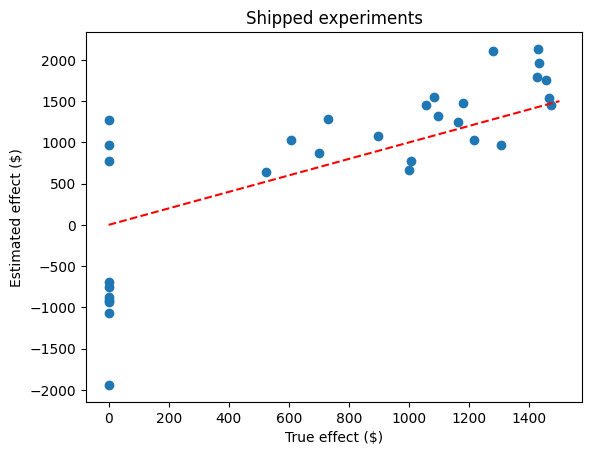

Overall inflation factor: 1.018x

Power group: low
Experiments shipped: 8
Average true effect: $927.68
Average estimated effect: $751.81
Inflation factor: 0.810x

Power group: medium
Experiments shipped: 10
Average true effect: $597.73
Average estimated effect: $677.99
Inflation factor: 1.134x

Power group: high
Experiments shipped: 13
Average true effect: $778.08
Average estimated effect: $857.95
Inflation factor: 1.103x


In [36]:
# plot estimates vs the truth
plt.scatter(shipped["true_effect"], shipped["estimated_effect"])
plt.plot([0, 1500], [0, 1500], "r--")
plt.xlabel("True effect ($)")
plt.ylabel("Estimated effect ($)")
plt.title("Shipped experiments")
plt.show()

# see how much bigger the average estimate is
inflation = shipped["estimated_effect"].mean() / shipped["true_effect"].mean()
print(f"Overall inflation factor: {inflation:.3f}x")

# find power of each test to detect a 1,000 dollar effect
target_effect = 1000
signal = target_effect / log["standard_error"]
cutoff = stats.norm.ppf(0.975)

log["power"] = stats.norm.sf(cutoff - signal) + stats.norm.cdf(-cutoff - signal)

# put the experiments into three equal sized power groups
log["power_group"] = pd.qcut(
    log["power"], 3, labels=["low", "medium", "high"]
)

# keep the shipped tests with power groups
shipped = log[log["p_value"] < 0.05]

# check the inflation in each group
for group in ["low", "medium", "high"]:
    tests = shipped[shipped["power_group"] == group]

    true_average = tests["true_effect"].mean()
    estimated_average = tests["estimated_effect"].mean()

    print("\nPower group:", group)
    print("Experiments shipped:", len(tests))
    print(f"Average true effect: ${true_average:,.2f}")
    print(f"Average estimated effect: ${estimated_average:,.2f}")

    if true_average > 0:
        print(f"Inflation factor: {estimated_average / true_average:.3f}x")
    else:
        print("Inflation factor: undefined because the average true effect is zero.")

*Your answer here.*

the average estimated effect was 1.018x the average true effect. the medium power group overstates by 13.4%, high 10.3%, and low understated by 19%. therefore this simulation did not show the expected patter thant inflation would be greater at the lower power. for a positive result to be counted as significant the estimate has to clear a threshold and low powered need the noise to help clear that threshold so selecting positive winners can exaggerate their effects. but the clinet also ships significant negative estimates and these pull the averages down and can hide expected upward selection pattern.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [37]:
# unshipped experiments return zero
returns = np.where(log["p_value"] < 0.05, log["true_effect"], 0)
print(f"Realised return: ${returns.sum():,.2f}")

# draw 2,000 new samples and add up each ones returns
boot_rng = np.random.default_rng(42)
boot_returns = []

for i in range(2000):
    sample = boot_rng.choice(returns, size=len(returns), replace=True)
    boot_returns.append(sample.sum())

boot_returns = np.array(boot_returns)

print("Manual percentile interval:", np.percentile(boot_returns, [2.5, 97.5]))

# check work with scipy
def total_return(x):
    return x.sum()

result = stats.bootstrap(
    (returns,),
    total_return,
    vectorized=False,
    n_resamples=2000,
    batch=1,
    method="BCa",
    random_state=np.random.default_rng(42)
)

# check both versions make same bootstrap draws
assert np.allclose(boot_returns, result.bootstrap_distribution)
print("Our bootstrap matches scipy.")

low = result.confidence_interval.low
high = result.confidence_interval.high
print(f"BCa 95% interval: [${low:,.2f}, ${high:,.2f}]")

# check that totals vary and the interval has actual numbers
assert boot_returns.std() > 0
assert (returns.sum() - returns).std() > 0
assert np.isfinite([low, high]).all()

print("All checks passed.")

Realised return: $23,513.73
Manual percentile interval: [13907.77571318 34005.57410293]
Our bootstrap matches scipy.
BCa 95% interval: [$14,623.09, $34,907.84]
All checks passed.


*Your answer here.*

the shipped experiments produced a realized return of 23513.73 dollars. my manual bootstrap matched scipys draws and gave a percentile interval of 13907.78 to 34005.57, and the bca 95% interval of 14,623.09 to 34,907.84. i checked for if the resampled totals changed, if leaving out an experiment could change the total, and if the interval contained valid numbers. i also made sure i was measuring total return and compared the intervals in case of skew in the results. these checks passed.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [38]:
# the client ships anything with p below 0.05
client = log[log["p_value"] < 0.05]

# my proposed rule needs p below 0.01 and a positive estimate
proposed = log[
    (log["p_value"] < 0.01) &
    (log["estimated_effect"] > 0)
]

print("Client rule")
print("Realised return:", client["true_effect"].sum())
print("Experiments shipped:", len(client))
print("False-ship rate:", (client["true_effect"] == 0).mean())

print("\nMy rule")
print("Realised return:", proposed["true_effect"].sum())
print("Experiments shipped:", len(proposed))
print("False-ship rate:", (proposed["true_effect"] == 0).mean())

Client rule
Realised return: 23513.730270811488
Experiments shipped: 31
False-ship rate: 0.3225806451612903

My rule
Realised return: 15136.705866996592
Experiments shipped: 14
False-ship rate: 0.07142857142857142


*Your answer here.*

my proposed rule requires p to be less than 0.01 and have a positive estimated effect. it shipped 14 experiments instead of 31 and decreased the false ship rate from 32.3% to 7.1%. but the realised return fell from 23513.73 to 15136.71. my proposed rule didnt win on total return because it rejected experiments that were helpful mixed in with the false ships. depending on the clients priorities of either total true return or rejecting false ships the original model may be better than the rule i proposed.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [39]:
%%writefile src/experiment_portfolio.py
"""Experiment-portfolio simulator and decision rules (ECON 5200 PS2)."""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats

def simulate_portfolio(n: int, seed: int, **kwargs):
    """Return the experiment log with the true effect attached."""
    rng = np.random.default_rng(seed)

    with_effect = rng.random(n) >= 0.80
    true_effect = np.zeros(n)
    true_effect[with_effect] = rng.uniform(500, 1500, with_effect.sum())

    sample_size = rng.integers(50, 5001, n)
    standard_error = 15000 * np.sqrt(2 / sample_size)
    estimated_effect = true_effect + rng.normal(0, standard_error)

    z = estimated_effect / standard_error
    p_value = 2 * stats.norm.sf(abs(z))

    log = pd.DataFrame({
        "experiment": np.arange(1, n + 1),
        "true_effect": true_effect,
        "n_per_group": sample_size,
        "standard_error": standard_error,
        "estimated_effect": estimated_effect,
        "p_value": p_value
    })

    return log


def apply_rule(log, rule):
    """Ship decisions under `rule`: the p < 0.05 threshold and at least one other."""
    if rule == "client":
        return log["p_value"] < 0.05
    elif rule == "proposed":
        return (log["p_value"] < 0.01) & (log["estimated_effect"] > 0)
    else:
        raise ValueError("Use client or proposed.")


def evaluate(log, rule):
    """Realised true return, ship count and false-ship rate under `rule`."""
    shipped = log[apply_rule(log, rule)]

    return {
        "realised_return": shipped["true_effect"].sum(),
        "ship_count": len(shipped),
        "false_ship_rate": (shipped["true_effect"] == 0).mean()
    }


if __name__ == "__main__":
    ...   # demonstration plus at least three assertions that must hold
    demo = simulate_portfolio(20, 99)
    print("Client:", evaluate(demo, "client"))
    print("Proposed:", evaluate(demo, "proposed"))

    # Check an example where we know the answers
    example = pd.DataFrame({
        "p_value": [0.001, 0.03, 0.50],
        "estimated_effect": [1200, 200, 100],
        "true_effect": [1000, 0, 0]
    })

    result = evaluate(example, "client")
    assert result["realised_return"] == 1000
    assert result["ship_count"] == 2
    assert result["false_ship_rate"] == 0.5

    print("All checks passed.")

Overwriting src/experiment_portfolio.py


In [40]:
import os, sys
import importlib
sys.path.insert(0, os.path.abspath('.'))
from src import experiment_portfolio as ep
importlib.reload(ep)
# prove it runs: call the three functions on a small portfolio

test_log = ep.simulate_portfolio(20, 100)
display(test_log.head())

print(ep.apply_rule(test_log, "client"))
print(ep.evaluate(test_log, "client"))
print(ep.evaluate(test_log, "proposed"))

,experiment,true_effect,n_per_group,standard_error,estimated_effect,p_value
0,1,1497.674,2467,427.092,1763.075,3.658e-05
1,2,0.000,4007,335.117,-274.543,4.126e-01
2,3,0.000,4820,305.550,-90.925,7.660e-01
3,4,0.000,3473,359.960,-238.136,5.083e-01
4,5,1478.622,3537,356.688,870.764,1.464e-02


0      True
1     False
2     False
3     False
4      True
5     False
6     False
7     False
8      True
9     False
10     True
11    False
12    False
13    False
14    False
15    False
16     True
17    False
18    False
19    False
Name: p_value, dtype: bool
{'realised_return': np.float64(5160.402328453203), 'ship_count': 5, 'false_ship_rate': np.float64(0.2)}
{'realised_return': np.float64(2859.855144291439), 'ship_count': 2, 'false_ship_rate': np.float64(0.0)}


In [41]:
!python src/experiment_portfolio.py

Client: {'realised_return': np.float64(1202.591146657982), 'ship_count': 2, 'false_ship_rate': np.float64(0.5)}
Proposed: {'realised_return': np.float64(1202.591146657982), 'ship_count': 1, 'false_ship_rate': np.float64(0.0)}
All checks passed.


## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [42]:
import numpy as np
from scipy import stats
from scipy.special import logsumexp


def sequential_test(stream, null_sd=1.0, alpha=0.05):
    """Return stopping decisions for independent normal observations.

    The null mean is zero, and null_sd is the known observation SD.
    Once the test stops, all later decisions stay True.
    """
    x = np.asarray(stream, dtype=float)

    if x.ndim != 1 or len(x) == 0 or not np.isfinite(x).all():
        raise ValueError("Pass a nonempty, finite one-dimensional stream.")

    if not np.isfinite(null_sd) or null_sd <= 0 or not 0 < alpha < 1:
        raise ValueError("Check null_sd and alpha.")

    # Standardize observations using the known SD
    n = np.arange(1, len(x) + 1)
    total = np.cumsum(x / null_sd)

    # Fix these possible effects before looking at any results
    effects = np.array([-0.20, -0.10, -0.05, 0.05, 0.10, 0.20])

    # Calculate each alternative's log likelihood ratio
    log_ratios = (
        effects[:, None] * total
        - 0.5 * effects[:, None]**2 * n
    )

    # Average the likelihood ratios safely in log space
    log_evidence = logsumexp(log_ratios, axis=0) - np.log(len(effects))

    # Stop the first time evidence reaches 1 / alpha
    crossed = log_evidence >= np.log(1 / alpha)

    return np.maximum.accumulate(crossed)

In [43]:
rng = np.random.default_rng(42)

n_trials = 1000
stream_length = 5000

sequential_errors = 0
naive_errors = 0

for i in range(n_trials):
    # Every experiment here has a true effect of zero
    stream = rng.normal(0, 1, stream_length)

    decisions = sequential_test(stream)
    sequential_errors += decisions.any()

    # Compare with repeatedly checking ordinary p-values
    n = np.arange(1, stream_length + 1)
    z = np.cumsum(stream) / np.sqrt(n)
    p_values = 2 * stats.norm.sf(abs(z))

    naive_errors += (p_values < 0.05).any()

false_positive_rate = sequential_errors / n_trials
mc_se = np.sqrt(
    false_positive_rate * (1 - false_positive_rate) / n_trials
)

print(f"Sequential false-positive rate: {false_positive_rate:.1%}")
print(f"Monte Carlo SE: {mc_se * 100:.2f} percentage points")
print(f"Naive repeated-testing rate: {naive_errors / n_trials:.1%}")

Sequential false-positive rate: 4.8%
Monte Carlo SE: 0.68 percentage points
Naive repeated-testing rate: 60.7%


In [44]:
# Use the SD from our portfolio simulation
def sequential_test_v2(stream, outcome_sd, alpha=0.05):
    """Test a stream of independent treatment-minus-control differences."""
    difference_sd = np.sqrt(2) * outcome_sd
    return sequential_test(stream, null_sd=difference_sd, alpha=alpha)


# Check it on 1,000 tests where the true effect is zero
rng_check = np.random.default_rng(42)
errors = 0

for i in range(1000):
    stream = rng_check.normal(0, np.sqrt(2) * 15000, 5000)
    decisions = sequential_test_v2(stream, outcome_sd=15000)
    errors += decisions.any()

false_positive_rate = errors / 1000
mc_se = np.sqrt(false_positive_rate * (1 - false_positive_rate) / 1000)

print("False positives:", errors)
print(f"False-positive rate: {false_positive_rate:.1%}")
print(f"Monte Carlo SE: {mc_se * 100:.2f} percentage points")

False positives: 48
False-positive rate: 4.8%
Monte Carlo SE: 0.68 percentage points


*Your answer here.*

1. revision: version 1 did not connnect null_sd to the simulation outcome_sd = 15000. i had to add a line that calculates sqrt(2)*outcome_sd so it handles the dollar value observations correctly.

2. check: the original test had a false positive of 4.8% and monte carlo se of 0.68pp. the revised gave the same digits, and both were close to the nominal 5% level. however the naive has a higher false positive rate of 60.7%.

3. in own words: crossed = log_evidence >= np.log(1 / alpha) checks whether the evidence has reached the stopping boundary. np.maximum.accumulate(crossed) keeps the decision true after the first crossing so the experiment stays stopped even if later evidence changes the decision to keep going.

4. would you use ai again? maybe to build help build the test but i still need to check the assumptions and null simulation before trusting it fully.


### Task 4.2: The CFO memo

*Your answer here.*

Of the 31 experiments shipped, 67.7% had a real positive effect and 32.3% had no effect at all. This means that a statistically significant result didnt always indicate a win. across 200 experiments per year, the current rule produces 23513.73 dollars in true additional revenue and the estimation is overstating the revenue by 434 dollars annually. The stricter rule proposed of p < 0.1 and a positive estimate shipped 14 experiments and reduced the false ship rate to 7.1% but only earlyed 15136.71 in true revenue. My recommendation is to keep the originally threshold if the priority is total revenue rather than adopting the proposed revenue which is stricter because it rejected genuine gains as a flaw. An assumption that could overturn this analysis is if deployment costs are negligible, because if launching experiements is expensive then shipping fewer would be more beneficial in a financial spotlight.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* ChatGPT 10/27

*Version 1 prompt:*

[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.

*Reply:*

Your prompt does not include the log’s columns or the observation model, so I need to make an assumption explicit: each stream contains independent observations with a known standard deviation, and the null mean is zero. The implementation below assumes normally distributed observations.

For an A/B test, the observations can be independent treatment-minus-control paired differences. In that case, null_sd must be the SD of those differences, not the SD of one arm.
1. Always-valid sequential test
This uses a two-sided mixture sequential probability ratio test. It returns one Boolean per observation: True means stop and reject the zero-effect null.
import numpy as npfrom scipy import statsfrom scipy.special import logsumexpdef sequential_test(stream, null_sd=1.0, alpha=0.05):    """Return stopping decisions for independent normal observations.    The null mean is zero, and null_sd is the known observation SD.    Once the test stops, all later decisions stay True.    """    x = np.asarray(stream, dtype=float)    if x.ndim != 1 or len(x) == 0 or not np.isfinite(x).all():        raise ValueError("Pass a nonempty, finite one-dimensional stream.")    if not np.isfinite(null_sd) or null_sd <= 0 or not 0 < alpha < 1:        raise ValueError("Check null_sd and alpha.")    # Standardize observations using the known SD    n = np.arange(1, len(x) + 1)    total = np.cumsum(x / null_sd)    # Fix these possible effects before looking at any results    effects = np.array([-0.20, -0.10, -0.05, 0.05, 0.10, 0.20])    # Calculate each alternative's log likelihood ratio    log_ratios = (        effects[:, None] * total        - 0.5 * effects[:, None]**2 * n    )    # Average the likelihood ratios safely in log space    log_evidence = logsumexp(log_ratios, axis=0) - np.log(len(effects))    # Stop the first time evidence reaches 1 / alpha


2. Verify on 1,000 null streams
Both methods below inspect the same streams after every observation.
rng = np.random.default_rng(42)n_trials = 1000stream_length = 5000sequential_errors = 0naive_errors = 0for i in range(n_trials):    # Every experiment here has a true effect of zero    stream = rng.normal(0, 1, stream_length)    decisions = sequential_test(stream)    sequential_errors += decisions.any()    # Compare with repeatedly checking ordinary p-values    n = np.arange(1, stream_length + 1)    z = np.cumsum(stream) / np.sqrt(n)    p_values = 2 * stats.norm.sf(abs(z))    naive_errors += (p_values < 0.05).any()false_positive_rate = sequential_errors / n_trialsmc_se = np.sqrt(    false_positive_rate * (1 - false_positive_rate) / n_trials)print(f"Sequential false-positive rate: {false_positive_rate:.1%}")print(f"Monte Carlo SE: {mc_se * 100:.2f} percentage points")print(f"Naive repeated-testing rate: {naive_errors / n_trials:.1%}")


I ran this code and measured:
Sequential false-positive rate: 4.8%
Monte Carlo SE: 0.68 percentage points
Naive repeated-testing rate: 60.7%

The sequential result is close to 5%—about 0.30 Monte Carlo standard errors below it. Nothing in this check suggests inflated Type I error.
3. Why it works—and the tradeoff
An ordinary p-value controls error at one planned look. Repeatedly checking it gives random noise many opportunities to cross the cutoff; those looks are correlated, but the overall false-positive probability still increases.

Under the stated normal null, each likelihood ratio is a nonnegative martingale starting at one, and their fixed average is too. Ville’s inequality therefore guarantees that the probability of ever crossing 1 / alpha is at most alpha, even with continuous monitoring. The mathematical guarantee—not the simulation—is what establishes validity. arxiv.org

The tradeoff is that the test generally needs more evidence than a single planned fixed-time test and can detect effects slowly when they differ from the mixture’s chosen alternatives. The guarantee is at most 5%, not exactly 5%. It also depends on the observation assumptions; replacing the known SD with a running sample SD would not automatically preserve it.

Your existing portfolio log can remain unchanged. However, final effect estimates and standard errors alone do not recover the actual observation streams needed to backtest early stopping. This method controls error within each experiment, not multiple testing across all 200 experiments.

*Version 2 prompt:*

can you revise the code to use my simulations outcome_sd = 15000? make sure it uses the correct SD for treatment-control differences then rerun the 1000 null streams to check the false positive rate.

*Reply:*

Version 2: keep the original sequential_test function, then add this cell. It supplies the correct SD and reruns the null check.

Use the SD from our portfolio simulationdef sequential_test_v2(stream, outcome_sd, alpha=0.05):    """Test a stream of independent treatment-minus-control differences."""    difference_sd = np.sqrt(2) * outcome_sd    return sequential_test(stream, null_sd=difference_sd, alpha=alpha)# Check it on 1,000 tests where the true effect is zerorng_check = np.random.default_rng(42)errors = 0for i in range(1000):    stream = rng_check.normal(0, np.sqrt(2) * 15000, 5000)    decisions = sequential_test_v2(stream, outcome_sd=15000)    errors += decisions.any()false_positive_rate = errors / 1000mc_se = np.sqrt(false_positive_rate * (1 - false_positive_rate) / 1000)print("False positives:", errors)print(f"False-positive rate: {false_positive_rate:.1%}")print(f"Monte Carlo SE: {mc_se * 100:.2f} percentage points")


I ran this and got:
False positives: 48
False-positive rate: 4.8%
Monte Carlo SE: 0.68 percentage points

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [45]:
print('Truth and headline numbers')
# print('prior on effects:', ..., '  set in Step 1.1')
# print('sample-size range:', ..., '  set in Step 1.1')
# print('seed:', 42, '  set in Setup')
# print('ship rule:', 'p < 0.05', '  Step 1.2')
# ... one line per memo number, with the cell that produced it

print("Zero-effect probability:", zero_share, "— Step 1.1")
print("Positive-effect probability:", 1 - zero_share, "— Step 1.1")
print("Positive effects: Uniform between", low_effect, "and", high_effect, "— Step 1.1")
print("Users per group:", n_min, "to", n_max, "inclusive — Step 1.1")
print("Outcome standard deviation:", outcome_sd, "— Step 1.1")
print("Observed estimates: true effect plus Normal noise with SD = standard error — Step 1.1")
print("Standard error: outcome_sd * sqrt(2 / sample_size) — Step 1.1")
print("Essentially zero means a true effect of exactly zero — Step 1.1")
print("Effect units: annual additional revenue dollars — Step 1.1")
print("Number of experiments:", n_experiments, "— Step 1.1")
print("Seed:", 42, "— Setup")

print("Client rule: p < 0.05, using two-sided p-values — Step 1.2")
print("Proposed rule: p < 0.01 and a positive estimate — Step 3.1")

annual_experiments = 200
annual_scale = annual_experiments / len(log)

forecast_gap = (
    client["estimated_effect"].sum() - client["true_effect"].sum()
) * annual_scale

print()
print("Annual experiments:", annual_experiments, "— CFO memo assumption")
print("Client ships:", len(client), "— Step 3.1")
print(f"Real wins: {(client['true_effect'] > 0).mean():.1%} — Step 1.2")
print(f"Client false-ship rate: {(client['true_effect'] == 0).mean():.1%} — Step 1.2")
print(f"Client annual true revenue: ${client['true_effect'].sum() * annual_scale:,.2f} — Step 3.1")
print(f"Annual forecast overstatement: ${forecast_gap:,.0f} — Steps 1.2 and 3.1")

print("Proposed ships:", len(proposed), "— Step 3.1")
print(f"Proposed false-ship rate: {(proposed['true_effect'] == 0).mean():.1%} — Step 3.1")
print(f"Proposed annual true revenue: ${proposed['true_effect'].sum() * annual_scale:,.2f} — Step 3.1")

print("Deployment costs were not simulated")

Truth and headline numbers
Zero-effect probability: 0.8 — Step 1.1
Positive-effect probability: 0.19999999999999996 — Step 1.1
Positive effects: Uniform between 500 and 1500 — Step 1.1
Users per group: 50 to 5000 inclusive — Step 1.1
Outcome standard deviation: 15000 — Step 1.1
Observed estimates: true effect plus Normal noise with SD = standard error — Step 1.1
Standard error: outcome_sd * sqrt(2 / sample_size) — Step 1.1
Essentially zero means a true effect of exactly zero — Step 1.1
Effect units: annual additional revenue dollars — Step 1.1
Number of experiments: 200 — Step 1.1
Seed: 42 — Setup
Client rule: p < 0.05, using two-sided p-values — Step 1.2
Proposed rule: p < 0.01 and a positive estimate — Step 3.1

Annual experiments: 200 — CFO memo assumption
Client ships: 31 — Step 3.1
Real wins: 67.7% — Step 1.2
Client false-ship rate: 32.3% — Step 1.2
Client annual true revenue: $23,513.73 — Step 3.1
Annual forecast overstatement: $434 — Steps 1.2 and 3.1
Proposed ships: 14 — Step 3

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.